# K-Means Clustering

**Objective:** Learn k-means clustering with simple, step-by-step examples.

## K-Means clustering

Clustering is an unsupervised task: there are no provided target labels. K-Means divides observations into K groups by assigning each point to its nearest centroid and repeatedly updating centroids to the mean of assigned points.

## K-Means Clustering
K-Means is an unsupervised algorithm. It groups similar rows without using labels during training.

### What is a centroid?

A centroid is the coordinate-wise average of points assigned to a cluster. It is a representative center, not necessarily an actual observation. K-Means alternates between assigning points and recalculating centroids until assignments or centroids stop changing substantially.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42

data = pd.read_csv('datasets/customer_segments.csv')
X = data[['feature_1', 'feature_2']]
data.head()

,feature_1,feature_2,cluster
0,-3.726,-2.936,0
1,-3.325,-1.153,0
2,-5.756,-3.172,0
3,-3.885,-2.285,0
4,-4.015,-2.768,0


### Objective function

K-Means minimizes within-cluster sum of squared distances (inertia): the sum, over all points, of squared distance to the assigned centroid. Smaller inertia generally occurs when K increases, so inertia alone cannot choose the right number of clusters.

In [2]:
model = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10)
data['predicted_cluster'] = model.fit_predict(X)
data.head()

,feature_1,feature_2,cluster,predicted_cluster
0,-3.726,-2.936,0,2
1,-3.325,-1.153,0,2
2,-5.756,-3.172,0,2
3,-3.885,-2.285,0,2
4,-4.015,-2.768,0,2


### Initialization and K-Means++

Poor starting centroids can lead to a weak local solution. K-Means++ chooses spread-out initial centers to improve the starting point. Because initialization is random, use `random_state` and consider multiple initializations.

In [3]:
score = silhouette_score(X, data['predicted_cluster'])
print('Silhouette score:', round(score, 3))

Silhouette score: 0.778


### Choosing K and scaling features

An elbow plot shows inertia for different K values; look for a point after which adding clusters gives diminishing improvement. Silhouette score measures how well a point fits its own cluster compared with nearby clusters. Scale features when units differ because distance depends on scale.

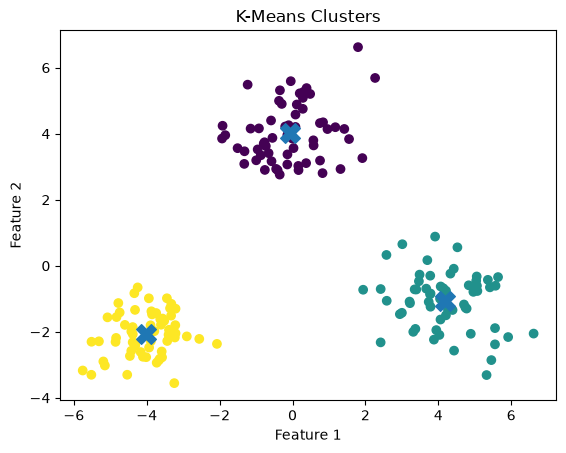

In [4]:
plt.scatter(data['feature_1'], data['feature_2'], c=data['predicted_cluster'])
plt.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1], marker='X', s=200)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('K-Means Clusters')
plt.show()

## Key terms and limitations

- **Unsupervised learning:** learning structure without target labels.
- **Centroid:** mean position of a cluster.
- **Inertia:** total within-cluster squared distance.
- **K-Means++:** initialization strategy that spreads starting centers.
- **Silhouette score:** measure of cohesion within clusters and separation from other clusters.

K-Means works best for roughly compact, similarly sized clusters and can struggle with irregular shapes, different densities, outliers and categorical-only data.

## Try This Yourself
- Try `n_clusters=2` and `n_clusters=4`.
- Compare silhouette scores.
- Explain what the cluster centers represent.